# Session 14 lab: From analysis to a decision dashboard

<p class="lead">
Turn analysis into something a busy manager can act on: declutter a chart, rewrite titles so they state a message, build a decision dashboard for one business case, write a big idea and an executive brief, check that everyone can read it, and repair a dashboard that misleads.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/14_dashboards_storytelling_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *Commercial lead: "Next week I present our plans to the leadership team. I need one page that shows where we stand, one sentence that says what we should do, and a short brief I can read out. Pick the case you know best and make it impossible to misunderstand."*

> **About the data**
>
> **Superstore** is a sample published by Tableau about a **fictitious** company. Sales and Profit are in the file's own **source monetary units**. The returns list says only **which orders** appear on it.
>
> **marketing-v1** is **synthetic** data generated by the course: seven paid campaigns, every day of 2025, amounts in neutral **currency units**. Attributed revenue is a synthetic single-campaign allocation; it does not prove a campaign **caused** a sale.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G3 |
| **Independent tasks** | Your own case, dashboard and brief, on your own or in pairs | I1–I4 |
| **Challenge** | Critique and repair, then plan a story | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Declutter a default chart: remove decoration, sort, use one highlight colour, label directly and keep honest axes.
2. Rewrite descriptive titles as message titles that are true for the data shown.
3. Lay out a multi-panel dashboard with `gridspec`, KPI tiles and a scope note.
4. Write a big-idea sentence and a five-sentence executive brief from your own outputs.
5. Check a dashboard for accessibility, including when colour is not available.
6. Find and fix the ways a dashboard can mislead.

**Evidence you keep:** your dashboard image, your big-idea sentence and your executive brief.

---

## Before you start

- Read the [Session 14 lecture](14_dashboards_storytelling_lecture.md).
- Have your dashboard from the [Session 7 lab](07_trends_and_growth_lab.md) to hand. If you choose the marketing case, re-read the [Session 12 lecture](12_marketing_campaigns_lecture.md).
- Re-read [Storytelling with data](../foundations/storytelling.md) and [Designing clear visuals](../foundations/visual-design.md).

---

## Guided practice

Run the two setup cells: the first prepares the retail orders, the second the marketing data (used only if you choose the marketing case in I1). Then run the cell that loads both.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [3]:
import re
import textwrap

import matplotlib.dates as mdates
import numpy as np
from matplotlib.ticker import StrMethodFormatter

THOUSANDS = StrMethodFormatter("{x:,.0f}")             # axis ticks like 20,000
GREY, BLUE, ORANGE, AQUA = "#b8b6b0", "#2a78d6", "#eb6834", "#1baf7a"

df = load_orders()
df["year"] = df["order_date"].dt.year
marketing = load_marketing("marketing_daily.csv")
print("Retail order lines:", len(df), "| orders:", df["order_id"].nunique())
print("Marketing rows:", len(marketing), "| campaigns:", marketing["campaign_id"].nunique(),
      "| days:", marketing["date"].nunique())

Retail order lines: 6815 | orders: 3388
Marketing rows: 2555 | campaigns: 7 | days: 365


### G1 (Core): Declutter a chart

The function below draws 2025 Sales by sub-category. Each switch turns on one decluttering step from the lecture. With every switch off, you get the cluttered default.

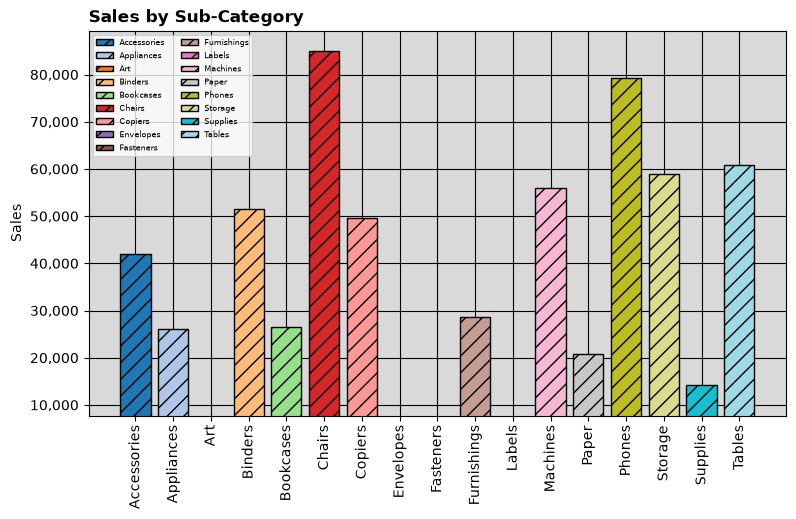

In [4]:
d25 = df[df["year"] == 2025]
sales_sub = d25.groupby("sub_category")["sales"].sum()


def sales_chart(remove_decoration=False, sort_horizontal=False, zero_baseline=False,
                grey_plus_one=False, direct_labels=False, focus=None, title="Sales by Sub-Category"):
    """2025 Sales by sub-category, with optional decluttering steps."""
    values = sales_sub.sort_values() if sort_horizontal else sales_sub
    if grey_plus_one:
        colours = [ORANGE if s == focus else GREY for s in values.index]
    elif remove_decoration:
        colours = BLUE
    else:
        colours = plt.cm.tab20(np.linspace(0, 1, len(values)))
    style = {} if remove_decoration else {"edgecolor": "black", "hatch": "//"}

    fig, ax = plt.subplots(figsize=(9, 5))
    if sort_horizontal:
        bars = ax.barh(values.index, values, color=colours, **style)
        value_axis, set_limits = ax.xaxis, ax.set_xlim
    else:
        bars = ax.bar(values.index, values, color=colours, **style)
        ax.tick_params(axis="x", rotation=90)
        value_axis, set_limits = ax.yaxis, ax.set_ylim

    if remove_decoration:
        ax.grid(axis="y" if sort_horizontal else "x", visible=False)
        unit = "Sales, 2025 (source monetary units)"
    else:
        ax.set_facecolor("#d9d9d9")
        ax.grid(True, color="black", linewidth=0.8)
        for spine in ax.spines.values():
            spine.set_visible(True)
        ax.legend(bars, values.index, fontsize=6, ncol=2)
        unit = "Sales"

    if zero_baseline:
        set_limits(0, values.max() * 1.2)
    else:
        set_limits(values.quantile(0.2), values.max() * 1.05)      # truncated: small bars vanish

    if direct_labels:
        for i, v in enumerate(values):
            if sort_horizontal:
                ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8)
            else:
                ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=7, rotation=90)
        value_axis.set_ticks([])
    else:
        value_axis.set_major_formatter(THOUSANDS)

    (ax.set_xlabel if sort_horizontal else ax.set_ylabel)(unit)
    ax.set_title(title)
    plt.show()


sales_chart()

List every problem you can see in the chart above before you change anything. Look for decoration, colour, order, the value axis and the title.

> **Your turn:** change the code in the next cell and run it again.

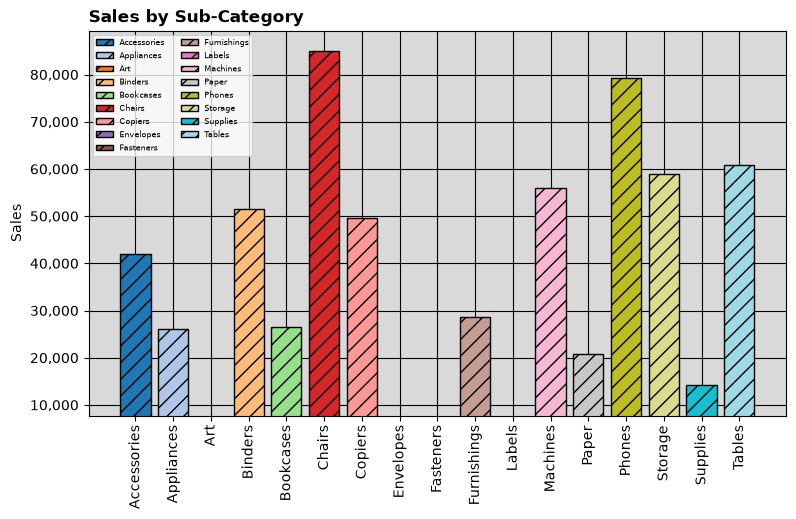

In [5]:
# 1. Set each switch to True, ONE at a time, and run the cell. Write down what each step improved.
# 2. Change focus to the sub-category your message is about (for example the largest, or one you are worried about).
# 3. Replace the title with a message title that is true for the chart, for example naming the leader.
sales_chart(
    remove_decoration=False,
    sort_horizontal=False,
    zero_baseline=False,
    grey_plus_one=False,
    direct_labels=False,
    focus="Chairs",
    title="Sales by Sub-Category",
)

> **Check before moving on**
>
> With every switch on, are any bars missing? Which switch brought back the small sub-categories, and what would a reader have concluded without it?

### G2 (Core): From descriptive to message titles

The cell below draws three charts with **descriptive** titles. Read each chart, then decide what a manager should notice.

In [6]:
monthly = df.groupby("order_month")["sales"].sum()
ratio_by_category = df.groupby("category")["profit"].sum() / df.groupby("category")["sales"].sum() * 100
ratio_by_category = ratio_by_category.sort_values()
ship_days = df.drop_duplicates("order_id").groupby("ship_mode")["order_to_ship_days"].median().sort_values()


def three_charts(titles):
    """Draw the three charts with the given titles (wrapped to fit)."""
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    axes[0].plot(monthly.index, monthly, color=BLUE)
    axes[0].set_ylabel("Sales (source monetary units)")
    axes[0].yaxis.set_major_formatter(THOUSANDS)
    axes[0].xaxis.set_major_locator(mdates.YearLocator())
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[0].set_xlabel("Order month")
    axes[1].barh(ratio_by_category.index, ratio_by_category, color=GREY)
    axes[1].set_xlabel("Profit ratio, 2023–2025 (%)")
    axes[2].barh(ship_days.index, ship_days, color=GREY)
    axes[2].set_xlabel("Median days from order to shipping")
    for ax, title in zip(axes, titles):
        ax.set_title(textwrap.fill(title, 38), fontsize=10)
    fig.tight_layout()
    plt.show()


print(ratio_by_category.round(1).to_string())
print(ship_days.to_string())

category
Furniture          3.10
Technology        16.90
Office Supplies   17.60
ship_mode
Same Day         0.00
First Class      2.00
Second Class     3.00
Standard Class   5.00


> **Your turn:** change the code in the next cell and run it again.

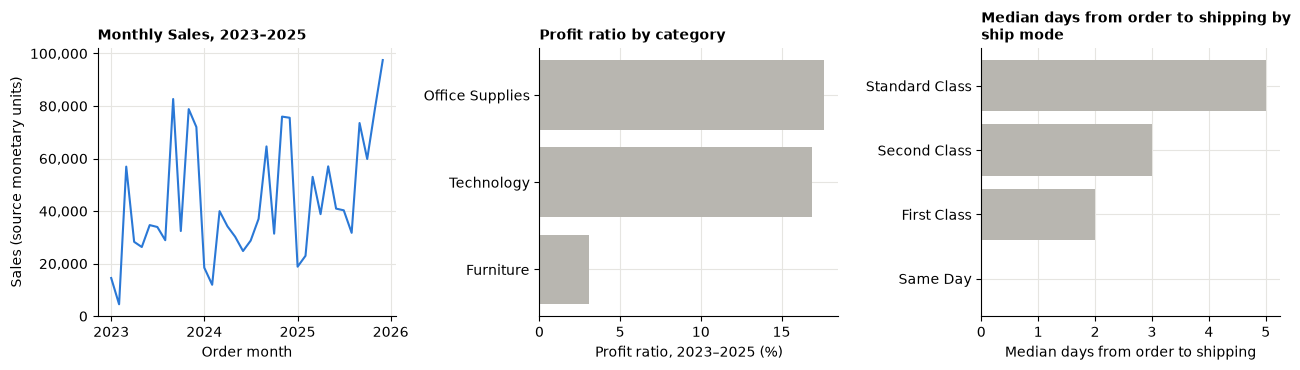

In [7]:
# 1. Run the cell to see the three charts with descriptive titles.
# 2. Replace each title with a MESSAGE title: what should the reader notice? Keep each true and checkable.
# 3. Optional: change the colour of the one bar your title is about to ORANGE in the function above.
titles = [
    "Monthly Sales, 2023–2025",
    "Profit ratio by category",
    "Median days from order to shipping by ship mode",
]
three_charts(titles)

> **Test your titles**
>
> Read only your three titles to a neighbour, without the charts. Can they tell you what the charts show? Then show the charts: do they agree the titles are true?

### G3 (Core): A three-panel dashboard with a scope note

A dashboard is one figure with several panels. `fig.add_gridspec(rows, columns)` splits the figure into a grid; `gs[0, :]` takes a whole row, `gs[1, 0]` one cell. Here the trend takes the full top row, two comparisons sit below it, and a thin bottom row holds the **scope note**.

The function takes the data and the scope note as arguments, so the same page can be redrawn for a filtered selection.

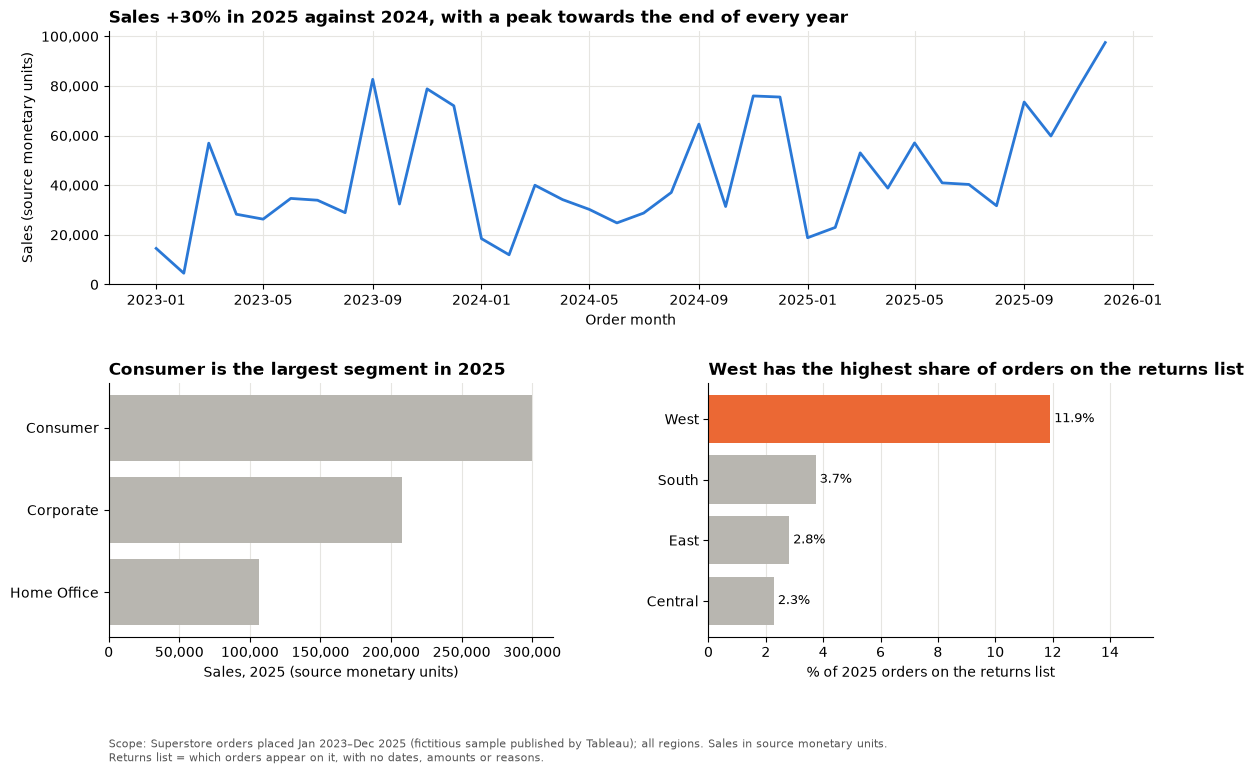

In [8]:
ALL_MONTHS = pd.date_range("2023-01-01", "2025-12-01", freq="MS")


def three_panel_dashboard(data, scope):
    """Monthly trend, segment Sales and returns-list share by region, with a scope note."""
    trend = data.groupby("order_month")["sales"].sum().reindex(ALL_MONTHS, fill_value=0)
    this_year = data[data["year"] == 2025]
    growth = this_year["sales"].sum() / data.loc[data["year"] == 2024, "sales"].sum() - 1
    segments = this_year.groupby("segment")["sales"].sum().sort_values()
    regions = (this_year[this_year["returned_order_flag"] == 1].groupby("region")["order_id"].nunique()
               / this_year.groupby("region")["order_id"].nunique()).fillna(0).sort_values()

    fig = plt.figure(figsize=(12, 8))
    gs = fig.add_gridspec(3, 2, height_ratios=[2, 2, 0.25], hspace=0.55, wspace=0.35)

    ax = fig.add_subplot(gs[0, :])
    ax.plot(trend.index, trend, color=BLUE, linewidth=2)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_title(f"Sales {growth:+.0%} in 2025 against 2024, with a peak towards the end of every year")
    ax.set_ylabel("Sales (source monetary units)")
    ax.set_xlabel("Order month")

    ax = fig.add_subplot(gs[1, 0])
    ax.barh(segments.index, segments, color=GREY)
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{segments.idxmax()} is the largest segment in 2025")
    ax.set_xlabel("Sales, 2025 (source monetary units)")

    ax = fig.add_subplot(gs[1, 1])
    ax.barh(regions.index, regions * 100, color=[ORANGE if r == regions.idxmax() else GREY for r in regions.index])
    for i, v in enumerate(regions):
        ax.text(v * 100, i, f" {v:.1%}", va="center", fontsize=9)
    ax.set_xlim(0, regions.max() * 100 * 1.3)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{regions.idxmax()} has the highest share of orders on the returns list")
    ax.set_xlabel("% of 2025 orders on the returns list")

    note = fig.add_subplot(gs[2, :])
    note.axis("off")
    note.text(0, 0.5, scope, fontsize=8, color="#555555", va="center", transform=note.transAxes)
    fig.subplots_adjust(left=0.1, right=0.97, top=0.95, bottom=0.03)
    plt.show()


scope_note = ("Scope: Superstore orders placed Jan 2023–Dec 2025 (fictitious sample published by Tableau); "
              "all regions. Sales in source monetary units.\nReturns list = which orders appear on it, "
              "with no dates, amounts or reasons.")
three_panel_dashboard(df, scope_note)

> **Your turn:** change the code in the next cell and run it again.

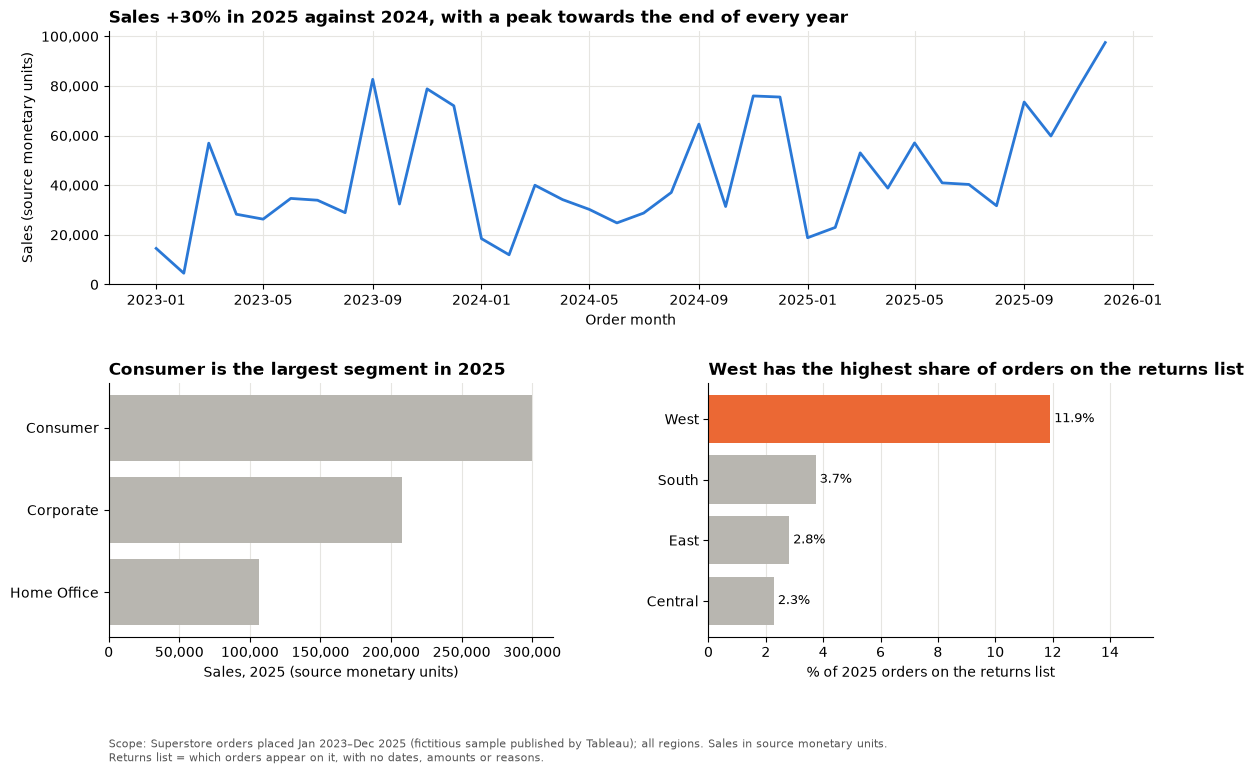

In [9]:
# 1. Change scope_note to "" (empty) and run. Which questions about the page can a reader no longer answer?
# 2. Restore the note. Then redraw the page for one segment: change "All" to "Consumer" (or another segment)
#    and add the segment to the scope note. Is every title still true? Rewrite any that is not.
segment = "All"
data = df if segment == "All" else df[df["segment"] == segment]
three_panel_dashboard(data, scope_note)

#### Design checks

- [ ] The most important view is at the top and the full width.
- [ ] Every title states a message and is true for the data shown.
- [ ] Every axis has a label with units; bars start at zero.
- [ ] Colour is used once, for the thing that needs attention.
- [ ] The scope note states the period, units, data source and the main limit.

---

## Independent tasks

### I1 (Core): A decision dashboard for your case

Choose **one** case:

| Case | Question for the leadership team | Data |
|---|---|---|
| `"retail"` (default) | Where should we focus next year, and what should we check before expanding? | Superstore, 2024–2025 |
| `"marketing"` | Which channels deserve more budget next year, and which need a review? | marketing-v1, 2025 |

The skeleton below has two parts. `case_inputs` calculates everything the page needs for your case: the KPI tiles, three views, default titles and the scope note. `decision_dashboard` draws the page from those inputs. Run it once to define both functions; you change only the **Your turn** cell after it.

In [10]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def case_inputs(case):
    """Everything the dashboard needs for one case: tiles, three views, default titles, scope and facts."""
    if case == "retail":
        d24, d25 = df[df["year"] == 2024], df[df["year"] == 2025]
        sales24, sales25 = d24["sales"].sum(), d25["sales"].sum()
        orders25 = d25["order_id"].nunique()
        listed25 = d25.loc[d25["returned_order_flag"] == 1, "order_id"].nunique()
        seg = (d25.groupby("segment")["sales"].sum() / d24.groupby("segment")["sales"].sum() - 1) * 100
        two = df[df["year"].isin([2024, 2025])].assign(month=lambda t: t["order_date"].dt.month)
        trend = two.pivot_table(index="month", columns="year", values="sales", aggfunc="sum")
        trend.columns = trend.columns.astype(str)
        reg = (d25[d25["returned_order_flag"] == 1].groupby("region")["order_id"].nunique()
               / d25.groupby("region")["order_id"].nunique()).fillna(0) * 100
        return {
            "tiles": [("Sales, 2025", f"{sales25:,.0f}", f"{sales25 / sales24 - 1:+.0%} vs 2024"),
                      ("Orders, 2025", f"{orders25:,}", f"{orders25 / d24['order_id'].nunique() - 1:+.0%} vs 2024"),
                      ("Profit ratio, 2025", f"{d25['profit'].sum() / sales25:.1%}",
                       f"{d24['profit'].sum() / sales24:.1%} in 2024"),
                      ("Orders on returns list, 2025", f"{listed25 / orders25:.1%}", f"{listed25} of {orders25:,} orders")],
            "compare": seg.sort_values(), "compare_label": "Sales growth, 2025 vs 2024 (%)", "compare_fmt": "{:+.0f}%",
            "trend": trend, "trend_label": "Sales (source monetary units)",
            "detail": reg.sort_values(), "detail_label": "% of 2025 orders on the returns list", "detail_fmt": "{:.1f}%",
            "titles": {"headline": "Retail dashboard, 2025",
                       "compare": "Sales growth by segment",
                       "trend": "Monthly Sales, 2024 and 2025",
                       "detail": "Share of orders on the returns list by region"},
            "highlight": {"compare": "Corporate", "detail": "West"},
            "scope": ("Scope: Superstore orders placed Jan 2024–Dec 2025 (fictitious sample published by Tableau). "
                      "Sales in source monetary units. Profit ratio = Profit ÷ Sales.\nReturns list = which orders "
                      "appear on it; no dates, amounts or reasons. Patterns describe what happened, not why."),
            "facts": [f"Sales 2025: {sales25:,.0f} ({sales25 / sales24 - 1:+.1%} vs 2024)",
                      f"Orders 2025: {orders25:,}",
                      "Sales growth by segment (%): " + ", ".join(f"{k} {v:+.1f}" for k, v in seg.items()),
                      f"Share of 2025 orders on the returns list: {listed25 / orders25:.1%}",
                      "By region (%): " + ", ".join(f"{k} {v:.1f}" for k, v in reg.sort_values().items()),
                      f"Months of 2025 above the same month of 2024: {int((trend['2025'] > trend['2024']).sum())} of 12"],
        }
    if case == "marketing":
        m = marketing
        ch = m.groupby("channel")[["spend", "conversions", "attributed_revenue"]].sum()
        roas = (ch["attributed_revenue"] / ch["spend"]).where(ch["spend"] > 0)          # ratio of sums
        cpa = (ch["spend"] / ch["conversions"]).where(ch["conversions"] > 0)
        by_month = m.groupby(m["date"].dt.month)[["spend", "attributed_revenue"]].sum()
        by_month.columns = ["Spend", "Attributed revenue"]
        spend, revenue, conversions = ch["spend"].sum(), ch["attributed_revenue"].sum(), ch["conversions"].sum()
        return {
            "tiles": [("Spend, 2025", f"{spend:,.0f}", "currency units"),
                      ("Attributed revenue, 2025", f"{revenue:,.0f}", "currency units"),
                      ("Return on ad spend", f"{revenue / spend:.2f}", "revenue per unit of spend"),
                      ("Cost per acquisition", f"{spend / conversions:,.2f}", "spend per conversion")],
            "compare": roas.sort_values(), "compare_label": "Attributed revenue per unit of spend (ROAS)",
            "compare_fmt": "{:.2f}",
            "trend": by_month, "trend_label": "Currency units",
            "detail": cpa.sort_values(), "detail_label": "Spend per conversion (CPA, currency units)",
            "detail_fmt": "{:,.0f}",
            "titles": {"headline": "Marketing dashboard, 2025",
                       "compare": "Return on ad spend by channel",
                       "trend": "Monthly spend and attributed revenue",
                       "detail": "Cost per acquisition by channel"},
            "highlight": {"compare": "Search", "detail": "Video"},
            "scope": (f"Scope: synthetic marketing-v1 data, {m['campaign_id'].nunique()} paid campaigns, every day of 2025. "
                      "Currency units. Rates are ratios of sums.\nAttributed revenue is a synthetic single-campaign "
                      "allocation, not proof of extra sales caused. Email has very little media spend."),
            "facts": [f"Spend 2025: {spend:,.0f} | attributed revenue: {revenue:,.0f} | ROAS: {revenue / spend:.2f}",
                      "ROAS by channel: " + ", ".join(f"{k} {v:.2f}" for k, v in roas.sort_values().items()),
                      "CPA by channel: " + ", ".join(f"{k} {v:,.1f}" for k, v in cpa.sort_values().items()),
                      "Share of spend by channel (%): " + ", ".join(
                          f"{k} {v:.1f}" for k, v in (ch["spend"] / spend * 100).sort_values().items()),
                      f"Highest-revenue month: {MONTH_NAMES[by_month['Attributed revenue'].idxmax() - 1]}"],
        }
    raise ValueError('case must be "retail" or "marketing"')


def kpi_tile(ax, label, value, note):
    """A text-only KPI tile: label, big number, comparison or unit."""
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#f3f2ef", zorder=0))
    ax.text(0.06, 0.78, label, transform=ax.transAxes, fontsize=9, color="#555555", va="center")
    ax.text(0.06, 0.46, value, transform=ax.transAxes, fontsize=17, fontweight="bold", va="center")
    ax.text(0.06, 0.16, note, transform=ax.transAxes, fontsize=9, color="#555555", va="center")


def ranked_bars(ax, values, highlight, fmt, label, title):
    """Sorted horizontal bars: grey context, one orange highlight, values written on the bars."""
    ax.barh(values.index, values, color=[ORANGE if k == highlight else GREY for k in values.index])
    for i, v in enumerate(values):
        ax.text(v, i, " " + fmt.format(v), va="center", ha="left" if v >= 0 else "right", fontsize=9)
    low = min(0, values.min() * 1.4)
    ax.set_xlim(low, max(values.max(), 0) * 1.35)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_xlabel(label)
    ax.set_title(textwrap.fill(title, 48))


def decision_dashboard(inputs, titles, highlight, show=True):
    """Draw the one-page dashboard: KPI tiles, a trend, two ranked comparisons and the scope note."""
    fig = plt.figure(figsize=(12, 10))
    gs = fig.add_gridspec(4, 4, height_ratios=[0.75, 2.1, 2.1, 0.3], hspace=0.5, wspace=0.45)
    for i, (label, value, note) in enumerate(inputs["tiles"]):
        kpi_tile(fig.add_subplot(gs[0, i]), label, value, note)

    ax = fig.add_subplot(gs[1, :])
    trend = inputs["trend"]
    for j, column in enumerate(trend.columns):
        last = j == len(trend.columns) - 1
        ax.plot(trend.index, trend[column], color=BLUE if last else GREY, linewidth=2.5 if last else 2,
                marker="o", markersize=4)
        ax.text(12.15, trend[column].iloc[-1], column, color=BLUE if last else "#777777", va="center",
                fontweight="bold" if last else "normal")
    ax.set_xticks(range(1, 13), MONTH_NAMES)
    ax.set_xlim(0.7, 13.2)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_ylabel(inputs["trend_label"])
    ax.set_title(titles["trend"])

    ranked_bars(fig.add_subplot(gs[2, :2]), inputs["compare"], highlight.get("compare"), inputs["compare_fmt"],
                inputs["compare_label"], titles["compare"])
    ranked_bars(fig.add_subplot(gs[2, 2:]), inputs["detail"], highlight.get("detail"), inputs["detail_fmt"],
                inputs["detail_label"], titles["detail"])

    note = fig.add_subplot(gs[3, :])
    note.axis("off")
    note.text(0, 0.5, inputs["scope"], fontsize=8, color="#555555", va="center", transform=note.transAxes)
    fig.suptitle(titles["headline"], x=0.02, y=0.96, ha="left", fontsize=14, fontweight="bold")
    fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.02)
    if show:
        plt.show()
    return fig


print("Dashboard functions ready.")

Dashboard functions ready.


> **Your turn:** change the code in the next cell and run it again.

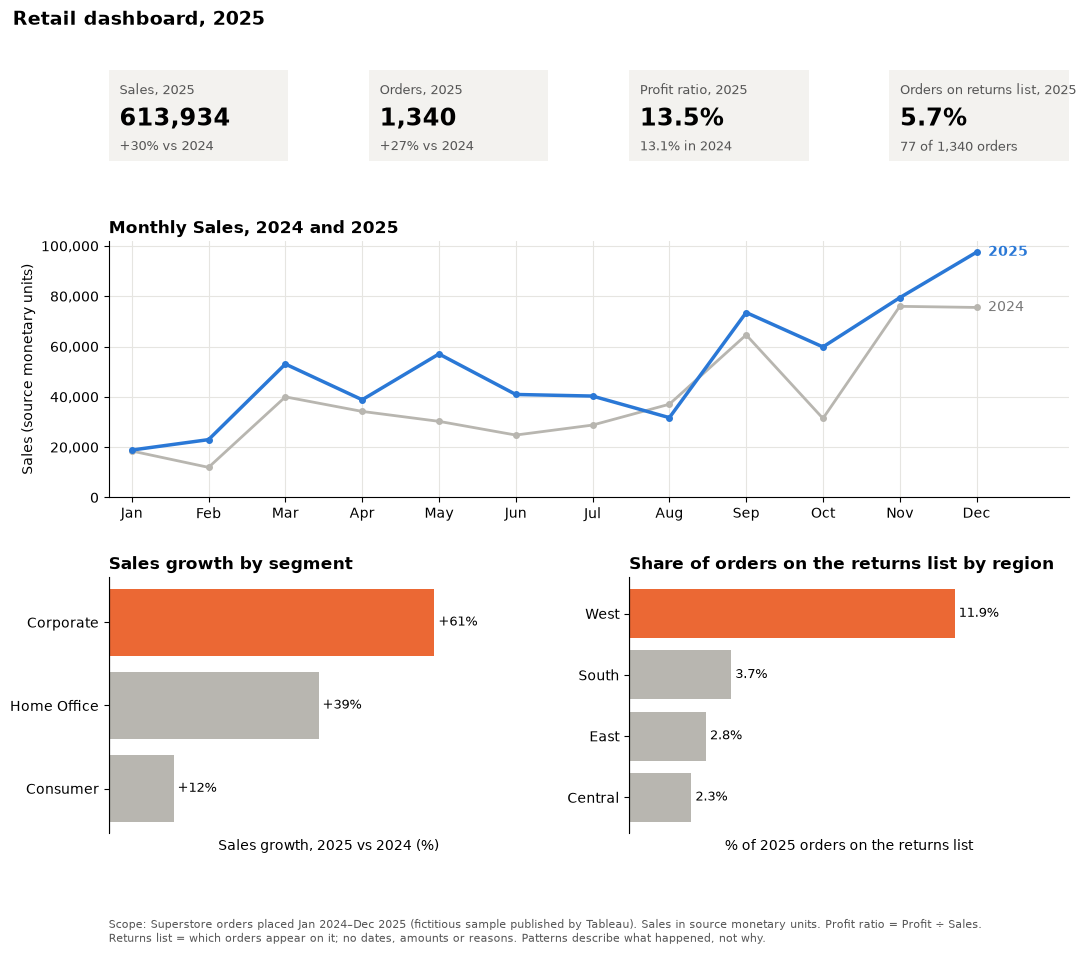

In [11]:
# 1. Run the cell as it is: the retail dashboard with DESCRIPTIVE default titles.
# 2. If you prefer, change CASE to "marketing" and run again. Stay with one case for the rest of the lab.
# 3. Replace the four titles with MESSAGE titles that are true for your case (start with the headline).
# 4. Change the highlights to the one bar in each chart that your message is about (or None for no highlight).
CASE = "retail"
inputs = case_inputs(CASE)

titles = dict(inputs["titles"])
# titles["headline"] = "Write your message headline here"
# titles["trend"] = "..."
# titles["compare"] = "..."
# titles["detail"] = "..."

highlight = dict(inputs["highlight"])
# highlight["compare"] = "..."

fig = decision_dashboard(inputs, titles, highlight)

Save the image of your dashboard for your evidence log: in Colab, right-click the figure and choose **Save image as**.

> **Marketing case: read carefully**
>
> If you chose marketing, look at where Email sits in the ROAS chart and read the scope note. A channel with almost no media spend can have an enormous ratio. Would you recommend moving most of the budget there? What does the CPA chart add?

### I2 (Core): Big idea and executive brief

The cell below prints a **fact sheet** for your case: the numbers you may quote. Every number in your writing must come from it (or from your dashboard).

In [12]:
print(f"Fact sheet: {CASE}")
for fact in inputs["facts"]:
    print("-", fact)

Fact sheet: retail
- Sales 2025: 613,934 (+29.8% vs 2024)
- Orders 2025: 1,340
- Sales growth by segment (%): Consumer +12.1, Corporate +60.8, Home Office +39.2
- Share of 2025 orders on the returns list: 5.7%
- By region (%): Central 2.3, East 2.8, South 3.7, West 11.9
- Months of 2025 above the same month of 2024: 11 of 12


Now write:

1. Your **big idea**: one sentence with a point of view, what is at stake, written for the leadership team.
2. A **five-sentence executive brief**: (1) recommendation; (2) and (3) evidence, each with a number and its comparison; (4) a risk or limit; (5) the next step.

The cell below checks the **shape** of your writing, not whether it is right: one sentence for the big idea, five sentences in the brief, and numbers in the two evidence sentences.

> **Your turn:** change the code in the next cell and run it again.

In [13]:
# 1. Replace the big idea and the five brief sentences with your own, using numbers from the fact sheet.
# 2. Run the cell and fix anything marked CHECK.
# 3. Read your big idea aloud. Could the commercial lead repeat it after hearing it once?
big_idea = "Write your one-sentence big idea here."
brief = [
    "Recommendation: write what the leadership team should do, and by when.",
    "Evidence: write the first number and what it is compared with.",
    "Evidence: write the second number and what it is compared with.",
    "Limit: write what the data cannot show, or what could change the answer.",
    "Next step: write the check or decision needed next, and who does it.",
]


def sentence_count(text):
    """Count sentences: a full stop, ! or ? followed by a space or the end (so 5.7% is not split)."""
    return len([s for s in re.split(r"[.!?](?:\s|$)", text) if s.strip()])


words = len(big_idea.split())
print("Big idea:", big_idea)
print("  sentences:", sentence_count(big_idea), "| words:", words,
      "| OK" if sentence_count(big_idea) == 1 and words <= 35 else "| CHECK: one sentence, at most about 35 words")
print("Brief sentences:", len(brief), "| OK" if len(brief) == 5 else "| CHECK: exactly five sentences")
for label, sentence in zip(["Evidence 1", "Evidence 2"], brief[1:3]):
    has_number = any(ch.isdigit() for ch in sentence)
    print(f"{label} quotes a number:", "OK" if has_number else "CHECK: add a number from the fact sheet")
print()
print("\n".join(brief))

Big idea: Write your one-sentence big idea here.
  sentences: 1 | words: 6 | OK
Brief sentences: 5 | OK
Evidence 1 quotes a number: CHECK: add a number from the fact sheet
Evidence 2 quotes a number: CHECK: add a number from the fact sheet

Recommendation: write what the leadership team should do, and by when.
Evidence: write the first number and what it is compared with.
Evidence: write the second number and what it is compared with.
Limit: write what the data cannot show, or what could change the answer.
Next step: write the check or decision needed next, and who does it.


> **Do not write**
>
> "West customers abuse returns." "Search causes most of our revenue." "Email is our best channel, so move the budget there." The data show **what** happened, not **why**, and attributed revenue is not proof of extra sales caused.

### I3 (Core): Accessibility check

Go through your dashboard with this list. Write **yes**, **no** or **fixed** next to each line in your evidence log.

- [ ] The headline and the KPI tiles can be read without looking at any chart.
- [ ] No more than five views (tiles count as one).
- [ ] Each colour means one thing everywhere on the page (grey = context, blue = the current period, orange = needs attention).
- [ ] Nothing is shown **only** by colour: every highlighted bar also has a number, a label or a position that says the same.
- [ ] No red–green pair is the only difference between two things.
- [ ] Text is large enough to read when the image is shrunk to half size.
- [ ] Every axis has a label with units; bars start at zero.
- [ ] The scope note gives period, units, data source and the main limit.

### I4 (Stretch): See your dashboard without colour

The cell below redraws your dashboard and converts it to shades of grey, roughly what a printout or a reader with very limited colour vision would see.

> **Your turn:** change the code in the next cell and run it again.

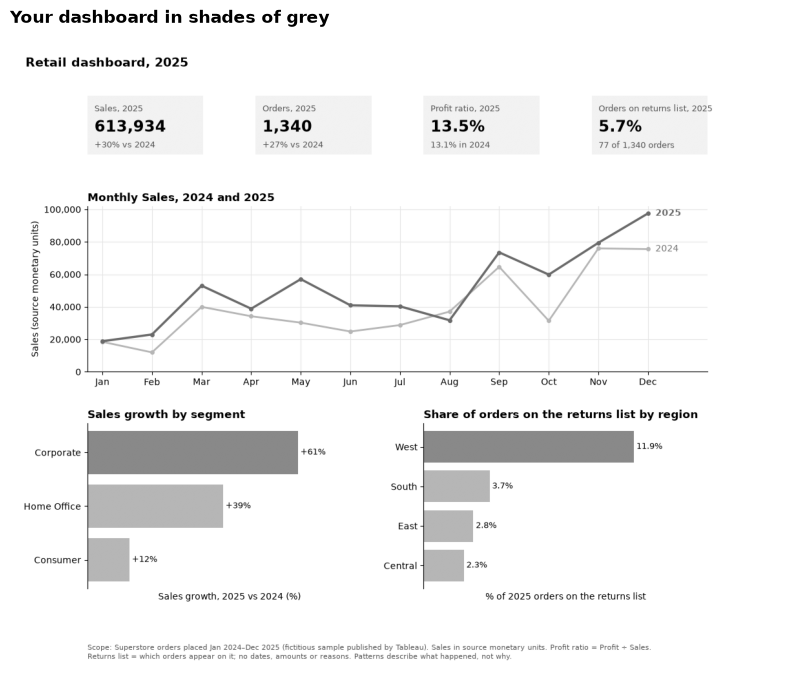

In [14]:
# 1. Run the cell. Can you still find the highlighted bar in each chart? How?
# 2. Change the highlight to another bar and run again. Is it still easy to find without colour?
# 3. If not, what would you add (a label, a bold name, an annotation)?
fig = decision_dashboard(inputs, titles, highlight, show=False)
fig.canvas.draw()
rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3] / 255
plt.close(fig)
grey_image = rgb @ np.array([0.299, 0.587, 0.114])     # standard brightness weights

fig, ax = plt.subplots(figsize=(10, 8.5))
ax.imshow(grey_image, cmap="gray", vmin=0, vmax=1)
ax.axis("off")
ax.set_title("Your dashboard in shades of grey")
plt.show()

---

## Challenge

### C1 (Challenge): Repair a misleading dashboard

A colleague made the dashboard below for a regional review. It contains **five** problems from this course:

| Problem | Where to look |
|---|---|
| A truncated axis | The region Sales bars |
| Colours with two meanings | Orange in each panel |
| A mean of rates | The returns-list tile |
| No scope note | The bottom of the page |
| A cherry-picked time window | The trend panel |

Run the cell first and write down what the page seems to say.

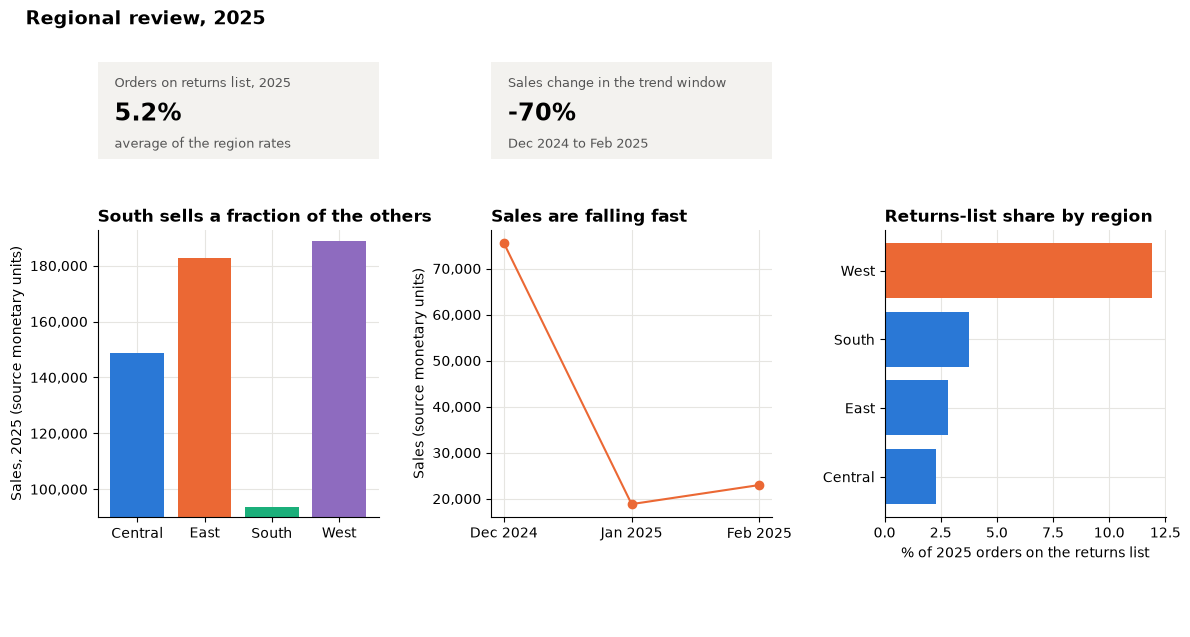

In [15]:
def risky_dashboard(fix_axis=False, fix_colours=False, fix_rate=False, add_scope=False, full_window=False):
    """A regional dashboard with five switchable problems."""
    d25 = df[df["year"] == 2025]
    region_sales = d25.groupby("region")["sales"].sum()
    orders = d25.groupby("region")["order_id"].nunique()
    listed = d25[d25["returned_order_flag"] == 1].groupby("region")["order_id"].nunique()
    share = (listed / orders).sort_values()
    overall = listed.sum() / orders.sum() if fix_rate else share.mean()
    monthly = df.groupby("order_month")["sales"].sum()
    window = monthly if full_window else monthly.loc["2024-12-01":"2025-02-01"]
    palette = {"Central": BLUE, "East": ORANGE, "South": AQUA, "West": "#8e6bbf"}

    fig = plt.figure(figsize=(12, 6.5))
    gs = fig.add_gridspec(3, 3, height_ratios=[0.75, 2.2, 0.3], hspace=0.5, wspace=0.4)
    kpi_tile(fig.add_subplot(gs[0, 0]), "Orders on returns list, 2025", f"{overall:.1%}",
             "listed orders ÷ all orders" if fix_rate else "average of the region rates")
    if full_window:                       # a fair headline: whole year against whole year
        yearly = df.groupby("year")["sales"].sum()
        kpi_tile(fig.add_subplot(gs[0, 1]), "Sales growth, 2025 vs 2024", f"{yearly[2025] / yearly[2024] - 1:+.0%}",
                 "full calendar years")
    else:                                 # first month shown against last month shown
        kpi_tile(fig.add_subplot(gs[0, 1]), "Sales change in the trend window",
                 f"{window.iloc[-1] / window.iloc[0] - 1:+.0%}", f"{window.index[0]:%b %Y} to {window.index[-1]:%b %Y}")

    ax = fig.add_subplot(gs[1, 0])
    colours = [ORANGE if r == "West" else GREY for r in region_sales.index] if fix_colours else \
        [palette[r] for r in region_sales.index]
    ax.bar(region_sales.index, region_sales, color=colours)
    if fix_axis:
        ax.set_ylim(0, region_sales.max() * 1.1)
        smallest, largest = region_sales.idxmin(), region_sales.idxmax()
        ax.set_title(f"{smallest} sold {region_sales.min() / region_sales.max():.0%} of {largest}'s Sales")
    else:
        ax.set_ylim(90_000, region_sales.max() * 1.02)
        ax.set_title("South sells a fraction of the others")
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_ylabel("Sales, 2025 (source monetary units)")

    ax = fig.add_subplot(gs[1, 1])
    ax.plot(window.index, window, color=BLUE if fix_colours else ORANGE, marker="o")
    ax.set_title("Sales repeat a winter dip every year" if full_window else "Sales are falling fast")
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_ylabel("Sales (source monetary units)")
    ax.set_xticks(pd.date_range("2023-01-01", "2026-01-01", freq="YS") if full_window else window.index)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    ax = fig.add_subplot(gs[1, 2])
    ax.barh(share.index, share * 100, color=[ORANGE if r == "West" else (GREY if fix_colours else BLUE)
                                              for r in share.index])
    ax.set_title("Returns-list share by region")
    ax.set_xlabel("% of 2025 orders on the returns list")

    note = fig.add_subplot(gs[2, :])
    note.axis("off")
    if add_scope:
        note.text(0, 0.5, "Scope: Superstore orders placed in 2025 (trend: Jan 2023–Dec 2025); fictitious sample "
                  "published by Tableau. Sales in source monetary units.\nOrange = West, the region that needs "
                  "attention. Returns list = which orders appear on it; no amounts or reasons.",
                  fontsize=8, color="#555555", va="center", transform=note.transAxes)
    fig.suptitle("Regional review, 2025", x=0.02, y=0.98, ha="left", fontsize=14, fontweight="bold")
    fig.subplots_adjust(left=0.08, right=0.97, top=0.9, bottom=0.03)
    plt.show()


risky_dashboard()

For each switch below:

1. Turn it on (`True`), run the cell and describe what changed: the number, the picture or the title.
2. Write one sentence on what a manager would have wrongly believed from the original.
3. With all five on, rewrite the page's headline as a message title that is true.

> **Your turn:** change the code in the next cell and run it again.

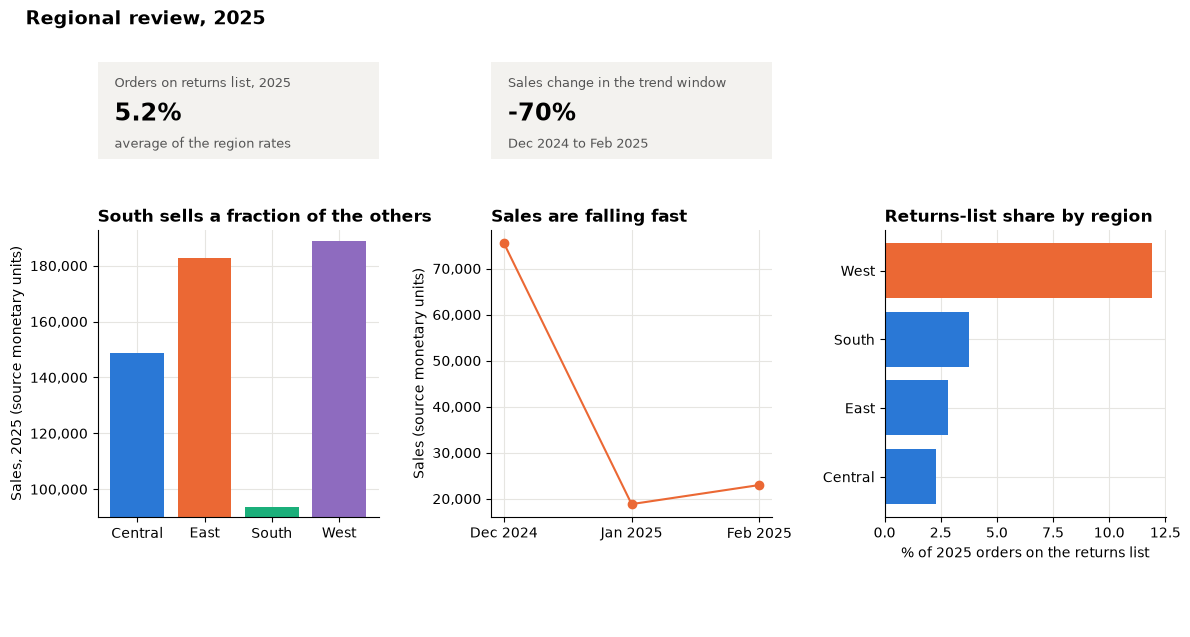

In [16]:
# Turn the switches on one at a time. Record before and after for each.
risky_dashboard(
    fix_axis=False,      # bars start at zero
    fix_colours=False,   # orange means "needs attention" (West) everywhere; grey for context
    fix_rate=False,      # overall share = listed orders ÷ all orders (a ratio of sums)
    add_scope=False,     # period, units, source, meaning of colour and limits
    full_window=False,   # all 36 months instead of three hand-picked ones
)

> **Hint**
>
> For the rate, compare the tile with the share of orders on the returns list in your I1 fact sheet (retail case). Which regions have the most orders, and does the plain average give them their fair weight? For the window, look back at the January dip in the Session 7 lab.

### C2 (Challenge): A three-slide story

Plan a three-slide story from your I1 dashboard, using **situation → complication → resolution**. For each slide write, in your evidence log:

| Slide | Message title (one sentence) | The one chart or number on it | What you will say (two sentences) |
|---|---|---|---|
| 1. Situation | | | |
| 2. Complication | | | |
| 3. Resolution | | | |

Rules: one message per slide; the titles read in order should tell the whole story; the resolution slide says what you need from the audience (a decision, a budget, a check) and what you **cannot** yet conclude.

---

## Validation checklist

- [ ] The decluttered chart has bars from zero, sorted, one highlight colour and a message title (G1).
- [ ] Each rewritten title is true for its chart and could be checked by a reader (G2).
- [ ] The three-panel dashboard has a scope note and every title was re-checked after filtering (G3).
- [ ] The decision dashboard has message titles, at most five views and consistent colours (I1).
- [ ] Every number in the big idea and the brief comes from the fact sheet or the dashboard (I2).
- [ ] Rates are ratios of sums, never averages of rates; blanks are "not available", never 0.
- [ ] The page works without colour (I3, I4).
- [ ] No sentence claims a cause that the data cannot show.

---

## Exit ticket

1. What is the difference between an exploratory and an explanatory chart?
2. Write the three parts of a good big-idea sentence.
3. Why did the "damaged flights only" view of the Challenger data hide the risk?
4. Give two ways to make a highlighted bar readable without colour.
5. Why is the average of four regional returns-list shares not the company's share?

---

## Evidence to keep

- [ ] Your decision dashboard image with message titles and a scope note (I1)
- [ ] Your big-idea sentence (I2)
- [ ] Your five-sentence executive brief (I2)
- [ ] Your accessibility check list (I3)
- [ ] Your before/after notes for the misleading dashboard and your three-slide outline (C1, C2, if attempted)

---

## After the lab

- Previous: [Session 14 lecture](14_dashboards_storytelling_lecture.md).
- Next: Session 15, the capstone: combining evidence across business areas.